# Movies dataset — Exploratory Data Analysis

Source: Kaggle, *Top 500–600 movies of each year* (`final_dataset.feather`).

1. Imports
2. Load the data
3. Overview: size, columns, data types, first rows
4. Missing values
5. Parse text columns into numbers
6. Convert non-USD budgets to USD
7. ROI
8. Feature dataset (numerical + categorical)
9. Pairwise plot
10. Correlation heatmap
11. ROI by genre
12. Linear regression of ROI
13. Errors

## 1. Imports

In [7]:
import ast
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from currency_converter import CurrencyConverter  

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid", context="notebook")

## 2. Load the data

In [8]:
df = pd.read_feather("final_dataset.feather")
df["release_date"] = pd.to_datetime(df["release_date"])

## 3. Overview

In [9]:
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
print(f"Release years: {df['release_date'].dt.year.min()}–{df['release_date'].dt.year.max()}")

Rows: 63,249   Columns: 23
Release years: 1920–2026


In [10]:
df.columns.tolist()

['id',
 'title',
 'duration',
 'mpa',
 'rating',
 'votes',
 'méta_score',
 'description',
 'movie_link',
 'writers',
 'directors',
 'stars',
 'budget',
 'opening_weekend_gross',
 'gross_worldwide',
 'gross_us_canada',
 'release_date',
 'countries_origin',
 'filming_locations',
 'production_companies',
 'awards_content',
 'genres',
 'languages']

In [11]:
df.dtypes

id                                 str
title                              str
duration                           str
mpa                                str
rating                         float64
votes                              str
méta_score                     float64
description                        str
movie_link                         str
writers                            str
directors                          str
stars                              str
budget                             str
opening_weekend_gross              str
gross_worldwide                    str
gross_us_canada                    str
release_date             datetime64[s]
countries_origin                   str
filming_locations                  str
production_companies               str
awards_content                     str
genres                             str
languages                          str
dtype: object

In [12]:
df.head()

,id,title,duration,mpa,rating,votes,méta_score,description,movie_link,writers,directors,stars,budget,opening_weekend_gross,gross_worldwide,gross_us_canada,release_date,countries_origin,filming_locations,production_companies,awards_content,genres,languages
0,tt0027483,The Crimson Circle,1h 16m,NaN,6.4,30,NaN,An extortion ring murders anyone who refuses to pay prot...,https://www.imdb.com/title/tt0027483/,"['Reginald Denham', 'Edgar Wallace', 'Howard Irving Young']",['Reginald Denham'],"['Hugh Wakefield', 'Alfred Drayton', 'Niall MacGinnis', ...",NaN,NaN,NaN,NaN,1936-08-10,['United Kingdom'],NaN,['Richard Wainwright Productions'],NaN,['Drama'],['English']
1,tt0058131,The Mystery of Thug Island,1h 36m,NaN,5.0,114,NaN,"Three year old Ada, daughter of the British captain McPh...",https://www.imdb.com/title/tt0058131/,"['Emilio Salgari', 'Arpad DeRiso', 'Ottavio Poggi']",['Luigi Capuano'],"['Guy Madison', 'Ingeborg Schöner', 'Giacomo Rossi Stuar...",NaN,NaN,NaN,NaN,1966-05-28,"['Italy', 'Monaco', 'West Germany']",NaN,"['Eichberg-Film', 'Liber Film']",NaN,['Adventure'],['Italian']
2,tt0042760,Las mujeres de mi general,1h 52m,Not Rated,6.8,74,NaN,Infante stars as a rebel general caught up in a tempestu...,https://www.imdb.com/title/tt0042760/,"['Joselito Rodríguez', 'Celestino Gorostiza', 'Ismael Ro...",['Ismael Rodríguez'],"['Pedro Infante', 'Lilia Prado', 'Chula Prieto', 'Miguel...",NaN,NaN,NaN,NaN,1951-07-13,['Mexico'],NaN,['Producciones Rodríguez Hermanos'],NaN,"['Drama', 'War']",['Spanish']
3,tt0027667,Gentle Julia,1h 2m,Approved,6.8,38,NaN,A shy newspaperman (Brown) nearly gives up when his girl...,https://www.imdb.com/title/tt0027667/,"['Booth Tarkington', 'Lamar Trotti']",['John G. Blystone'],"['Jane Withers', 'Tom Brown', 'Marsha Hunt', 'Jackie Sea...",NaN,NaN,NaN,NaN,1936-04-10,['United States'],"['20th Century Fox Studios - 10201 Pico Blvd., Century C...",['Twentieth Century Fox'],NaN,"['Comedy', 'Drama', 'Romance']",['English']
4,tt0055747,Love at Twenty,1h 50m,NaN,7.2,2.5K,NaN,"""Love at Twenty"" unites five directors from around the w...",https://www.imdb.com/title/tt0055747/,"['Shintarô Ishihara', 'Marcel Ophüls', 'Renzo Rossellini']","['Shintarô Ishihara', 'Marcel Ophüls', 'Renzo Rossellini']","['Jean-Pierre Léaud', 'Marie-France Pisier', 'Patrick Au...",NaN,NaN,NaN,NaN,1963-02-06,"['France', 'Italy', 'Japan', 'Poland', 'West Germany']","['Warsaw Zoo, Ratuszowa, Praga Pólnoc, Warsaw, Mazowieck...","['Ulysse Productions', 'Unitec Films', 'Cinesecolo']",NaN,"['Drama', 'Romance']","['French', 'Polish', 'Japanese', 'Italian', 'German']"


In [15]:
df.loc[37021]

id                                                                        tt28131433
title                                     Legends of the Condor Heroes: The Gallants
duration                                                                      2h 26m
mpa                                                                                R
rating                                                                           6.8
votes                                                                           2.7K
méta_score                                                                       NaN
description              The Mongols, led by Genghis Khan, went west to destroy t...
movie_link                                    https://www.imdb.com/title/tt28131433/
writers                                                   ['Louis Cha', 'Hark Tsui']
directors                                                              ['Hark Tsui']
stars                    ['Zhan Xiao', 'Dafei Zhuang', 'Tony Ka F

## 4. Missing values

In [7]:
missing = (
    df.isna().sum()
      .to_frame("n_missing")
      .assign(pct_missing=lambda t: (100 * t["n_missing"] / len(df)).round(1))
      .sort_values("n_missing", ascending=False)
)
missing

,n_missing,pct_missing
awards_content,63249,100.0
budget,47890,75.7
méta_score,47716,75.4
opening_weekend_gross,46412,73.4
gross_us_canada,43705,69.1
gross_worldwide,42527,67.2
mpa,22022,34.8
filming_locations,16854,26.6
rating,4068,6.4
votes,4068,6.4


`awards_content` is entirely empty and is dropped later.

## 5. Parse text columns into numbers

| column | raw | parsed |
|---|---|---|
| money columns | `$65,000,000 (estimated)`, `€2,300,000` | currency code + amount |
| `votes` | `1.3K`, `2M` | 1300, 2000000 |
| `duration` | `1h 16m` | 76 (minutes) |

A few rows have an MPA rating in the `duration` column (shifted data); those become `NaN`.

In [9]:
# Currency prefix as written in the data -> ISO code
CURRENCY = {"$": "USD", "€": "EUR", "£": "GBP", "CA$": "CAD", "₹": "INR", "A$": "AUD",
            "¥": "JPY", "₩": "KRW", "CN¥": "CNY", "HK$": "HKD", "NZ$": "NZD",
            "R$": "BRL", "MX$": "MXN", "₪": "ILS", "₱": "PHP"}


def parse_money(s):
    """'€2,300,000 (estimated)' -> ('EUR', 2300000.0); missing -> (None, NaN)."""
    if not isinstance(s, str):
        return None, np.nan
    m = re.match(r"^\s*([^\d\s]*)\s*([\d,]+)", s)
    if not m:
        return None, np.nan
    prefix, amount = m.groups()
    return CURRENCY.get(prefix, prefix), float(amount.replace(",", ""))


def parse_votes(s):
    if not isinstance(s, str):
        return np.nan
    mult = {"K": 1e3, "M": 1e6}.get(s[-1], 1)
    return float(s.rstrip("KM")) * mult


def parse_duration(s):
    if not isinstance(s, str):
        return np.nan
    m = re.fullmatch(r"(?:(\d+)h)?\s?(?:(\d+)m)?", s.strip())
    if not m or not any(m.groups()):
        return np.nan
    h, mins = (int(x) if x else 0 for x in m.groups())
    return 60 * h + mins


money_cols = ["budget", "opening_weekend_gross", "gross_worldwide", "gross_us_canada"]
for c in money_cols:
    parsed = df[c].map(parse_money)
    df[c + "_cur"] = parsed.str[0]
    df[c + "_amt"] = parsed.str[1]

df["votes_n"] = df["votes"].map(parse_votes)
df["duration_min"] = df["duration"].map(parse_duration)
df["year"] = df["release_date"].dt.year
df["month"] = df["release_date"].dt.month

df["budget_cur"].value_counts().head(10)

budget_cur
USD    13091
EUR      565
GBP      377
CAD      331
INR      202
AUD      115
FRF      110
DEM       92
SEK       57
FIM       44
Name: count, dtype: int64

## 6. Convert non-USD budgets to USD

About 15% of budgets are in other currencies. They are converted with the European Central Bank daily rates bundled in `currencyconverter`, using the rate on the film's release date.

Those rates start in 1999, so a non-USD budget is converted only if the film was released in 1999 or later and its currency is covered. Older ones (and pre-euro currencies such as FRF, DEM, ITL) stay `NaN`. Applying a 1999 rate to a 1970 budget would be wrong.

The gross columns are almost entirely in USD; the handful that are not are set to `NaN`.

In [10]:
cc = CurrencyConverter(fallback_on_missing_rate=True)   # fills weekend/holiday gaps


def to_usd(amount, cur, date):
    if pd.isna(amount) or cur is None:
        return np.nan
    if cur == "USD":
        return amount
    if cur not in cc.currencies:
        return np.nan
    first, last = cc.bounds[cur]
    if not (first <= date.date() <= last):
        return np.nan
    return cc.convert(amount, cur, "USD", date=date.date())


df["budget_usd"] = [to_usd(a, c, d) for a, c, d in
                    zip(df["budget_amt"], df["budget_cur"], df["release_date"])]

for c in ["opening_weekend_gross", "gross_worldwide", "gross_us_canada"]:
    df[c + "_usd"] = df[c + "_amt"].where(df[c + "_cur"] == "USD")

print(f"Budgets in USD originally: {(df['budget_cur'] == 'USD').sum():,}")
print(f"Budgets after conversion:  {df['budget_usd'].notna().sum():,}")

Budgets in USD originally: 13,091
Budgets after conversion:  14,131


## 7. ROI

`roi = gross_us_canada / budget` (both in USD).

Some budgets are recorded as $1 or a few hundred dollars, which gives absurd ROI values. The table below shows the extremes before filtering.

In [11]:
df["roi"] = df["gross_us_canada_usd"] / df["budget_usd"]

df.loc[df["roi"].notna(), ["title", "year", "budget", "gross_us_canada", "roi"]] \
  .sort_values("roi", ascending=False).head(10)

,title,year,budget,gross_us_canada,roi
53897,Tadap,2021,₹20 (estimated),"$130,934",491947.599725
60212,Sarileru Neekevvaru,2020,₹260 (estimated),"$821,000",224040.703481
141,Radical Wolfe,2023,$1 (estimated),"$39,623",39623.000000
37021,Legends of the Condor Heroes: The Gallants,2025,CN¥500 (estimated),"$671,343",9736.281657
22260,Paranormal Activity,2009,"$15,000 (estimated)","$107,918,810",7194.587333
26981,League of Gods,2016,HK$300 (estimated),"$181,633",4696.775827
16528,Tarnation,2004,$220 (estimated),"$592,014",2690.972727
16924,The Blair Witch Project,1999,"$60,000 (estimated)","$140,539,099",2342.318317
11467,El Mariachi,1993,"$7,000 (estimated)","$2,040,920",291.560000
1521,The Gallows,2015,"$100,000 (estimated)","$22,764,410",227.644100


Keep ROI only where the budget is at least **$10,000**. Because ROI is heavy-tailed, the median is a better summary than the mean.

In [12]:
MIN_BUDGET = 10_000
df.loc[df["budget_usd"] < MIN_BUDGET, "roi"] = np.nan

print(f"Movies with ROI: {df['roi'].notna().sum():,}")
print(f"Median ROI: {df['roi'].median():.2f}   Mean ROI: {df['roi'].mean():.2f}")
print(f"Share with ROI > 1 (US/Canada gross exceeds budget): {(df['roi'] > 1).mean() / df['roi'].notna().mean():.1%}")

Movies with ROI: 9,264
Median ROI: 0.67   Mean ROI: 3.07
Share with ROI > 1 (US/Canada gross exceeds budget): 40.1%


## 8. Feature dataset (numerical + categorical)

Dropped as free text or identifiers: `id`, `title`, `description`, `movie_link`, `writers`, `directors`, `stars`, `filming_locations`, `production_companies`, `awards_content`.

List-like columns (`genres`, `countries_origin`, `languages`) are stored as strings such as `"['Drama', 'War']"`. They are parsed into real lists, and the first entry is kept as a single category.

`mpa` has many historical labels; they are grouped into G / PG / PG-13 / R / Other.

In [13]:
def parse_list(s):
    if not isinstance(s, str):
        return []
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError):
        return []


MPA_GROUP = {"G": "G", "PG": "PG", "GP": "PG", "M": "PG", "M/PG": "PG",
             "PG-13": "PG-13", "R": "R", "NC-17": "R", "X": "R"}

data = pd.DataFrame({
    "rating":                df["rating"],
    "meta_score":            df["méta_score"],
    "votes":                 df["votes_n"],
    "duration_min":          df["duration_min"],
    "year":                  df["year"],
    "month":                 df["month"],
    "budget_usd":            df["budget_usd"],
    "opening_weekend_usd":   df["opening_weekend_gross_usd"],
    "gross_worldwide_usd":   df["gross_worldwide_usd"],
    "gross_us_canada_usd":   df["gross_us_canada_usd"],
    "roi":                   df["roi"],
    "mpa":                   df["mpa"].map(MPA_GROUP).fillna("Other"),
})

for c in ["genres", "countries_origin", "languages"]:
    data[c] = df[c].map(parse_list)
    data[c.split("_")[0] + "_main"] = data[c].str[0]

cat_cols = ["mpa", "genres_main", "countries_main", "languages_main"]
data[cat_cols] = data[cat_cols].astype("category")
data["mpa"] = data["mpa"].cat.reorder_categories(["G", "PG", "PG-13", "R", "Other"])

num_cols = data.select_dtypes("number").columns.tolist()
print(data.shape)
data.head()

(63249, 18)


,rating,meta_score,votes,duration_min,year,month,budget_usd,opening_weekend_usd,gross_worldwide_usd,gross_us_canada_usd,roi,mpa,genres,genres_main,countries_origin,countries_main,languages,languages_main
0,6.4,NaN,30.0,76.0,1936,8,NaN,NaN,NaN,NaN,NaN,Other,[Drama],Drama,[United Kingdom],United Kingdom,[English],English
1,5.0,NaN,114.0,96.0,1966,5,NaN,NaN,NaN,NaN,NaN,Other,[Adventure],Adventure,"[Italy, Monaco, West Germany]",Italy,[Italian],Italian
2,6.8,NaN,74.0,112.0,1951,7,NaN,NaN,NaN,NaN,NaN,Other,"[Drama, War]",Drama,[Mexico],Mexico,[Spanish],Spanish
3,6.8,NaN,38.0,62.0,1936,4,NaN,NaN,NaN,NaN,NaN,Other,"[Comedy, Drama, Romance]",Comedy,[United States],United States,[English],English
4,7.2,NaN,2500.0,110.0,1963,2,NaN,NaN,NaN,NaN,NaN,Other,"[Drama, Romance]",Drama,"[France, Italy, Japan, Poland, West Germany]",France,"[French, Polish, Japanese, Italian, German]",French


In [14]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
rating,59181.0,6.162731e+00,1.070630e+00,1.000000,5.500000e+00,6.300000e+00,6.900000e+00,1.000000e+01
meta_score,15533.0,5.907120e+01,1.740303e+01,1.000000,4.700000e+01,6.100000e+01,7.200000e+01,1.000000e+02
votes,59181.0,1.819399e+04,8.467172e+04,5.000000,1.630000e+02,7.270000e+02,4.400000e+03,3.000000e+06
duration_min,61086.0,9.584080e+01,3.634697e+01,1.000000,8.200000e+01,9.300000e+01,1.050000e+02,5.220000e+03
year,63249.0,1.973266e+03,3.068713e+01,1920.000000,1.947000e+03,1.974000e+03,2.000000e+03,2.026000e+03
month,63249.0,6.597733e+00,3.520427e+00,1.000000,3.000000e+00,7.000000e+00,1.000000e+01,1.200000e+01
budget_usd,14131.0,1.912033e+07,3.464360e+07,0.049072,1.100000e+06,6.000000e+06,2.000000e+07,4.149000e+08
opening_weekend_usd,16837.0,4.940692e+06,1.464693e+07,11.000000,1.122700e+04,8.451200e+04,3.424702e+06,3.571150e+08
gross_worldwide_usd,20709.0,3.549177e+07,1.172936e+08,1.000000,9.500000e+04,1.659542e+06,1.798923e+07,2.923711e+09
gross_us_canada_usd,19538.0,1.707460e+07,4.716121e+07,1.000000,6.503925e+04,7.325240e+05,1.209683e+07,9.366622e+08


## 9. Pairwise plot

- Only movies with an ROI are plotted, so every panel shows the same films.
- Votes, budget, gross and ROI span several orders of magnitude, so they are shown as `log10`.
- Points are coloured by MPA rating group.

Text(0.5, 1.01, 'Pairwise relationships (n = 9,264 movies with ROI)')

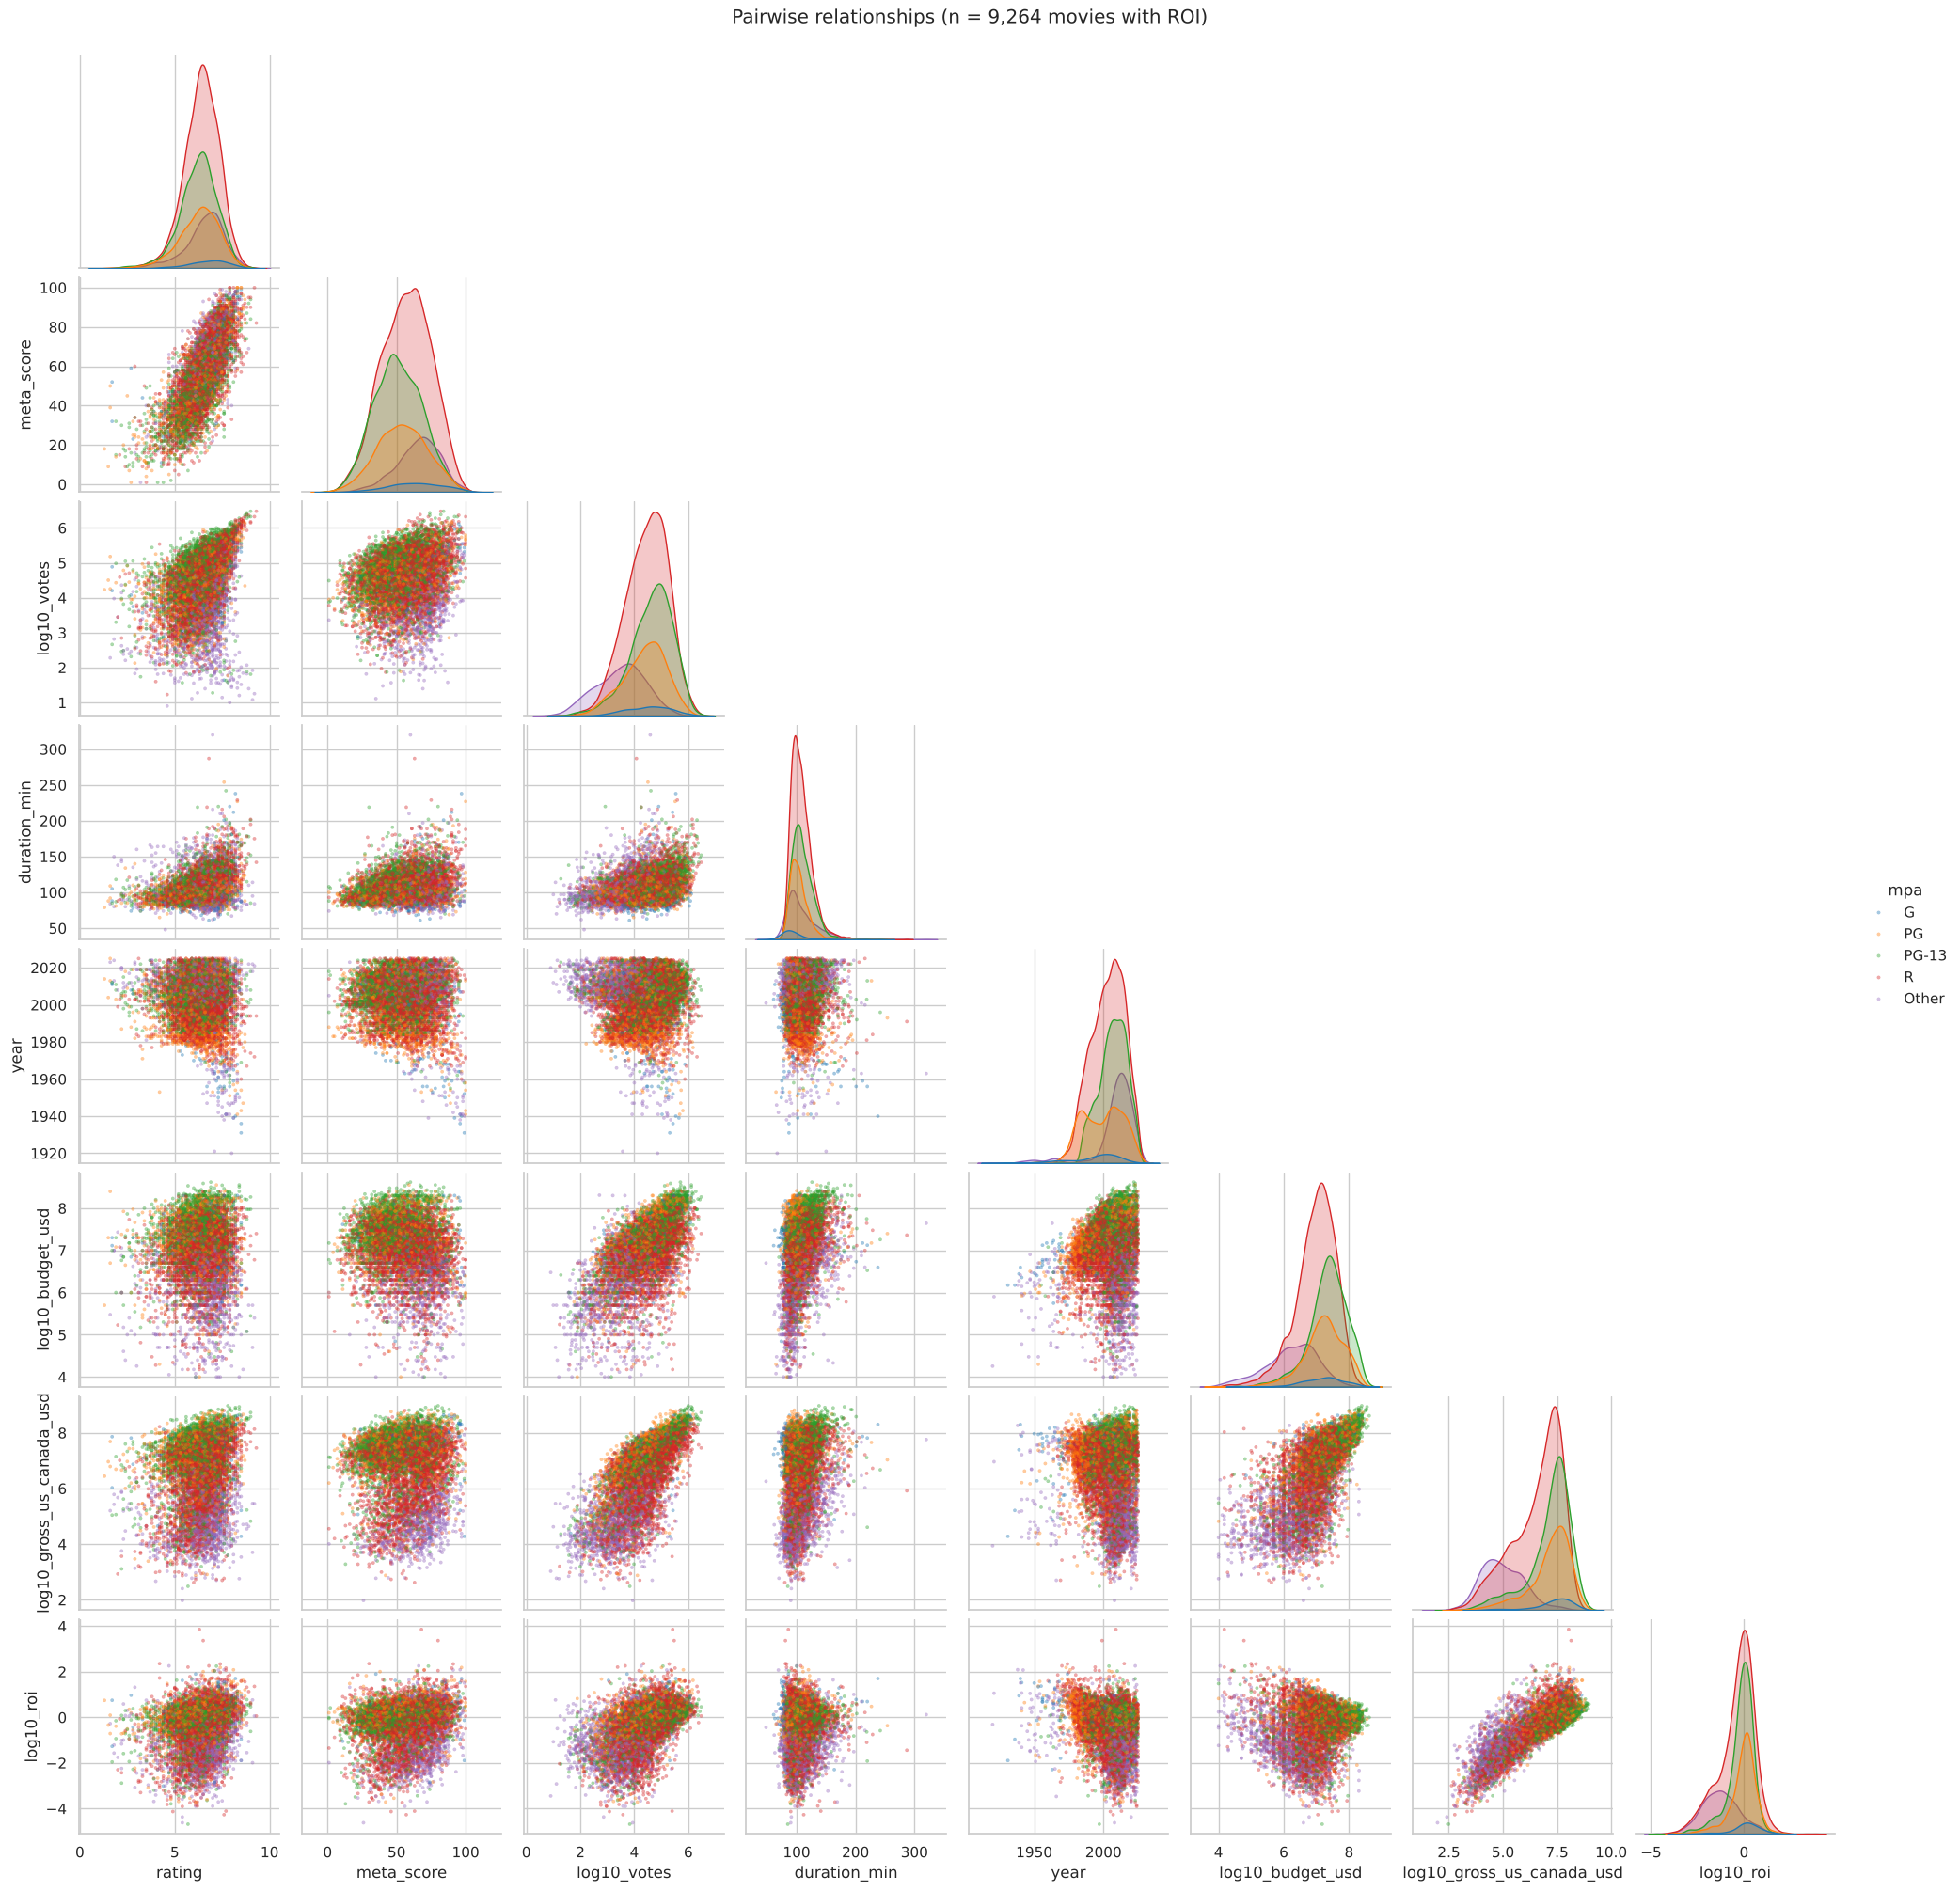

In [15]:
pair_cols = ["rating", "meta_score", "votes", "duration_min", "year",
             "budget_usd", "gross_us_canada_usd", "roi"]
log_cols = ["votes", "budget_usd", "gross_us_canada_usd", "roi"]

p = data.loc[data["roi"].notna(), pair_cols + ["mpa"]].copy()
p[log_cols] = np.log10(p[log_cols])
p = p.rename(columns={c: f"log10_{c}" for c in log_cols})

g = sns.pairplot(p, hue="mpa", corner=True, diag_kind="kde",
                 palette="tab10", plot_kws=dict(s=6, alpha=0.4, edgecolor=None))
g.figure.suptitle(f"Pairwise relationships (n = {len(p):,} movies with ROI)", y=1.01)

## 10. Correlation heatmap

Spearman (rank) correlation, which is unaffected by the log transform and robust to the heavy tails.

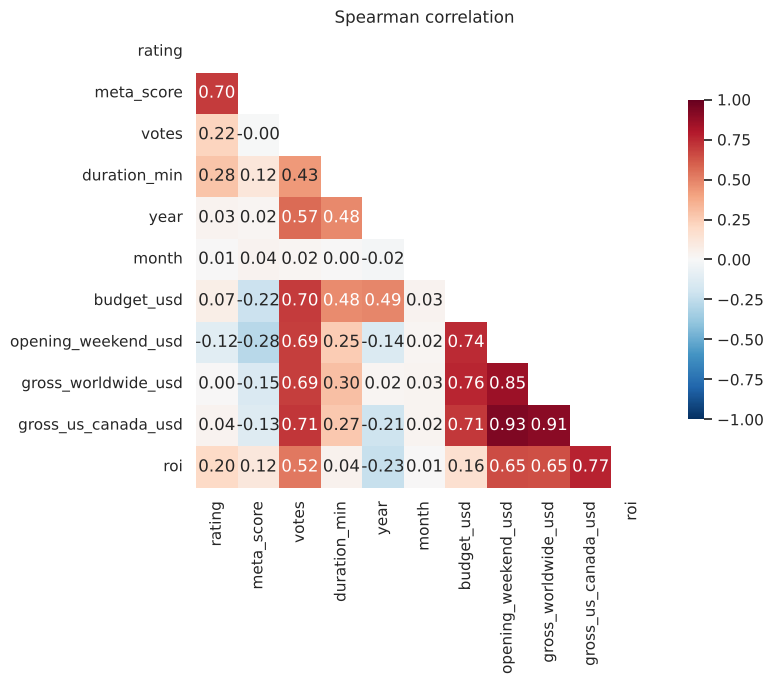

In [16]:
corr = data[num_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, square=True, cbar_kws=dict(shrink=0.7), ax=ax)
ax.grid(False)
ax.set_title("Spearman correlation")
plt.tight_layout()

## 11. ROI by genre

A film has several genres, so each film is counted once per genre (`explode`). IMDb genres include many sub-genres; only genres with at least 300 films are shown.

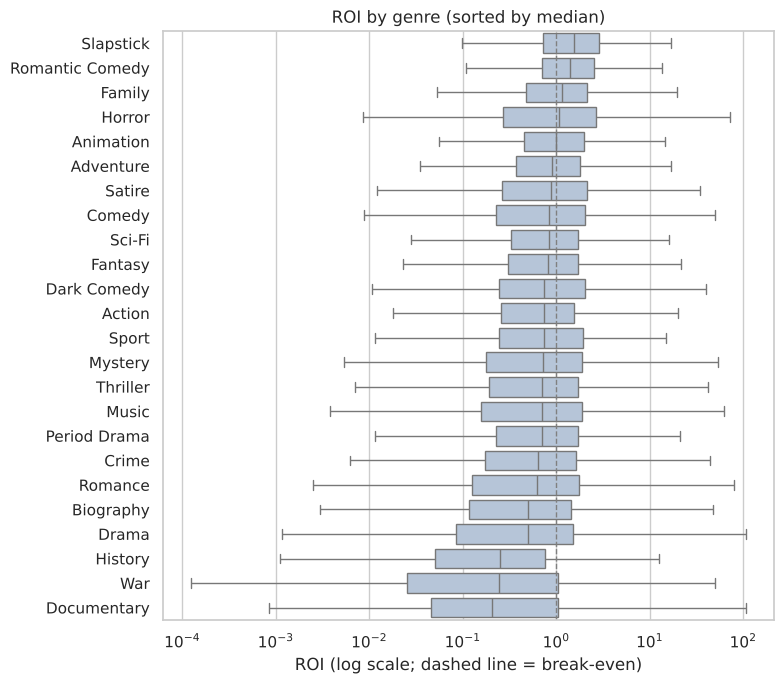

In [17]:
g = (
    data.loc[data["roi"].notna(), ["genres", "roi"]]
        .explode("genres")
        .dropna(subset=["genres"])
)
summary = (
    g.groupby("genres")["roi"]
     .agg(n="size", median_roi="median")
     .query("n >= 300")
     .sort_values("median_roi", ascending=False)
)

order = summary.index.tolist()
fig, ax = plt.subplots(figsize=(8, 7))
sns.boxplot(data=g[g["genres"].isin(order)], y="genres", x="roi", order=order,
            log_scale=True, showfliers=False, color="lightsteelblue", ax=ax)
ax.axvline(1, color="gray", ls="--", lw=1)
ax.set_xlabel("ROI (log scale; dashed line = break-even)")
ax.set_ylabel("")
ax.set_title("ROI by genre (sorted by median)")
plt.tight_layout()

In [18]:
summary.round(2)

,n,median_roi
genres,,
Slapstick,322,1.56
Romantic Comedy,346,1.40
Family,871,1.14
Horror,997,1.06
Animation,411,1.00
Adventure,1574,0.90
Satire,354,0.89
Comedy,3512,0.85
Sci-Fi,948,0.85


## 12. Linear regression of ROI

**Target: `log10(roi)`.** ROI is heavily right-skewed (median 0.67, max in the thousands). On the raw scale a handful of hits would dominate the least-squares fit; on the log scale the residuals are roughly symmetric and a coefficient reads as a multiplicative effect on ROI.

**Features excluded to avoid leakage.** Since `roi = gross_us_canada / budget`, we have `log roi = log gross − log budget` exactly. Including US/Canada gross alongside budget would give R² ≈ 1 without learning anything. The worldwide and opening-weekend grosses are excluded as well: they are near-copies of US/Canada gross (Spearman 0.91 and 0.93).

**Features used**

| type | features |
|---|---|
| numerical | `rating`, `meta_score`, `log10(votes)`, `duration_min`, `year`, `month`, `log10(budget_usd)` |
| categorical | `mpa` (5 groups), `countries_main` (top 10 + Other) |
| genres | one indicator column per genre with at least 300 films (a film can have several) |

Missing numerical values are filled with the training median, and a 0/1 "was missing" indicator is added. This matters mostly for `meta_score`. Numerical features are standardised so the coefficients are comparable.

In [19]:
model_df = data.loc[data["roi"].notna()].copy()
model_df["log_votes"] = np.log10(model_df["votes"])
model_df["log_budget"] = np.log10(model_df["budget_usd"])
y = np.log10(model_df["roi"])

# Countries: keep the 10 most common, group the rest
top_countries = model_df["countries_main"].value_counts().index[:10]
model_df["country"] = model_df["countries_main"].astype(str).where(
    model_df["countries_main"].isin(top_countries), "Other")

# Genres: one 0/1 column per common genre
genre_counts = model_df["genres"].explode().value_counts()
top_genres = genre_counts[genre_counts >= 300].index
for gname in top_genres:
    model_df[f"g_{gname}"] = model_df["genres"].map(lambda lst: gname in lst).astype(int)

num_features = ["rating", "meta_score", "log_votes", "duration_min", "year", "month", "log_budget"]
cat_features = ["mpa", "country"]
genre_features = [f"g_{g}" for g in top_genres]

X = model_df[num_features + cat_features + genre_features]
print(f"Movies: {len(X):,}   Features before encoding: {X.shape[1]}")
X[num_features].isna().mean().round(3).rename("share_missing")

Movies: 9,264   Features before encoding: 33


rating          0.000
meta_score      0.159
log_votes       0.000
duration_min    0.000
year            0.000
month           0.000
log_budget      0.000
Name: share_missing, dtype: float64

Hold out 20% of the films as a test set. The model is fitted on the training set only.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
     num_features),
    ("cat", OneHotEncoder(drop=["G", "United States"], handle_unknown="ignore"), cat_features),
    ("genre", "passthrough", genre_features),
])
model = make_pipeline(preprocess, LinearRegression())
model.fit(X_train, y_train)

print(f"Train: {len(X_train):,}   Test: {len(X_test):,}")

Train: 7,411   Test: 1,853


### Coefficients

Each coefficient is the change in `log10(roi)` per one standard deviation of a numerical feature, or for switching a category or genre on. A coefficient of 0.1 multiplies ROI by 10^0.1 ≈ 1.26, i.e. +26%.

Reference categories: MPA **G** and country **United States**. Other categories are measured relative to these.

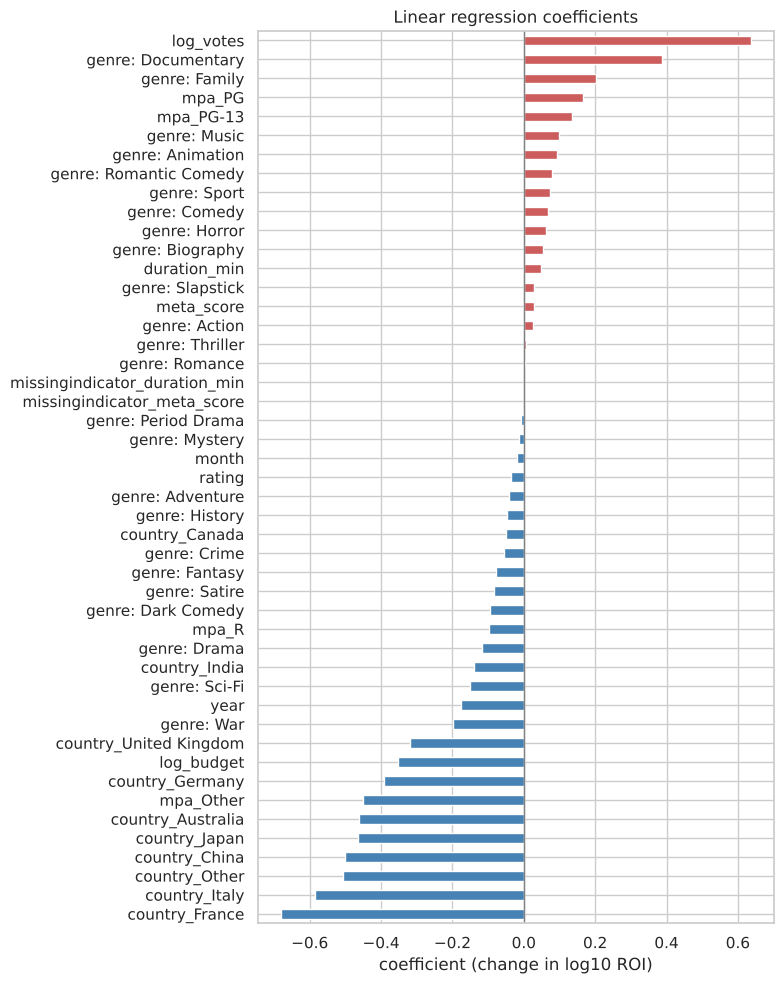

In [21]:
names = model[0].get_feature_names_out()
coefs = pd.Series(model[-1].coef_, index=names)
coefs.index = (coefs.index.str.replace(r"^(num|cat|genre)__", "", regex=True)
                          .str.replace("^g_", "genre: ", regex=True))
coefs = coefs.sort_values()

fig, ax = plt.subplots(figsize=(8, 10))
coefs.plot.barh(ax=ax, color=np.where(coefs > 0, "indianred", "steelblue"))
ax.axvline(0, color="gray", lw=1)
ax.set_xlabel("coefficient (change in log10 ROI)")
ax.set_title("Linear regression coefficients")
plt.tight_layout()

## 13. Errors

Errors are reported on the log scale (the scale the model was fitted on), for both training and test sets. A baseline that always predicts the training mean is included for comparison.

- **RMSE / MAE** in log10 units: an MAE of 0.5 means predictions are typically off by a factor of 10^0.5 ≈ 3.2.
- **R²**: share of the variance in `log10(roi)` explained.

In [22]:
def errors(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)
baseline = np.full_like(y_test, y_train.mean())

results = pd.DataFrame({
    "train": errors(y_train, pred_train),
    "test": errors(y_test, pred_test),
    "baseline (test)": errors(y_test, baseline),
}).T.round(3)
results["MAE as ROI factor"] = (10 ** results["MAE"]).round(2)
results

,RMSE,MAE,R2,MAE as ROI factor
train,0.662,0.479,0.510,3.01
test,0.683,0.489,0.498,3.08
baseline (test),0.963,0.744,-0.000,5.55


Train and test errors are close, so the model is not overfitting. The remaining error is noise the features do not capture.

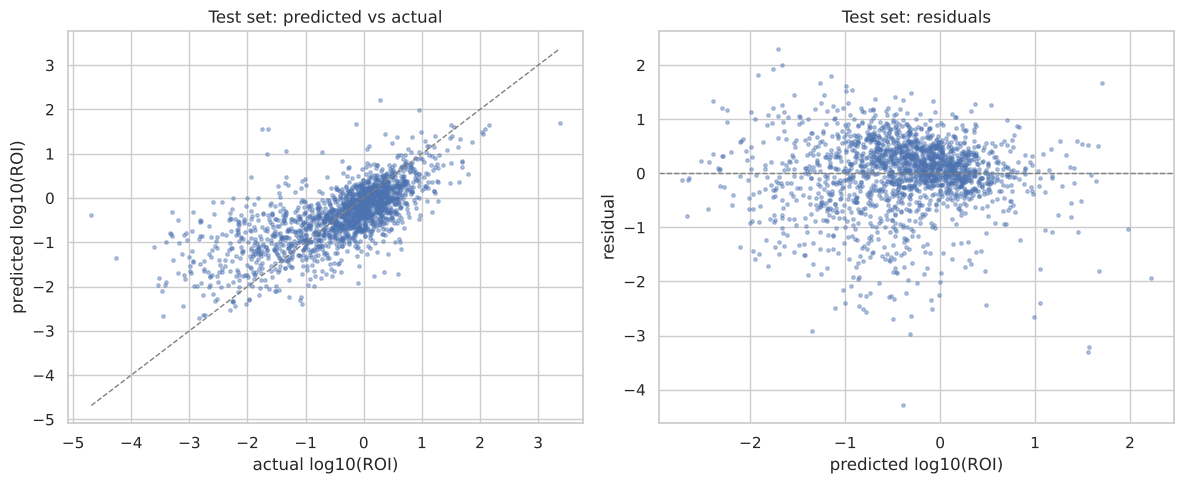

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.scatter(y_test, pred_test, s=6, alpha=0.4)
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ax.plot(lims, lims, color="gray", ls="--", lw=1)
ax.set_xlabel("actual log10(ROI)")
ax.set_ylabel("predicted log10(ROI)")
ax.set_title("Test set: predicted vs actual")

ax = axes[1]
resid = y_test - pred_test
ax.scatter(pred_test, resid, s=6, alpha=0.4)
ax.axhline(0, color="gray", ls="--", lw=1)
ax.set_xlabel("predicted log10(ROI)")
ax.set_ylabel("residual")
ax.set_title("Test set: residuals")

plt.tight_layout()